# Harder repair case: reviewer results

This notebook reports the predeclared six-session comparison on a second learned checkpoint with two introduced weaknesses. Both reviewers received the same staged instructions and evidence budgets within each condition. Results below are from a fresh held-out split, evaluated only after the planned cohort and any missing sessions were frozen.

**Observed on 4,096 held-out inputs:** Astra's edits improved accuracy by 3.59–3.96 percentage points; its weights-only and adaptive results differed by one example. Qwen improved by 0.05 points with weights only, 1.44 with fixed probes, and 0.73 with adaptive probes. These are descriptive results from one conversation per condition, so they do not establish that probes caused the differences.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=Path.cwd().resolve()
if not (ROOT/'experiment.json').exists(): ROOT=ROOT.parent
report=json.loads((ROOT/'results/repair_v2_study.json').read_text())
rows=report['sessions']; OUT=ROOT/'results/figures';OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':300,'axes.spines.top':False,'axes.spines.right':False})
def save(fig,name):
    fig.savefig(OUT/f'{name}.png',bbox_inches='tight',facecolor='white');fig.savefig(OUT/f'{name}.svg',bbox_inches='tight',facecolor='white')
def label(r):return ('Astra' if r['reviewer']=='gpt-6.2-astra' else 'Qwen')+' / '+r['condition'].replace('_',' ')
print('Held-out examples:',report['sample_count'])

Held-out examples: 4096


## 1. Session results

The change is the edited model's accuracy minus the starting model's accuracy on exactly the same inputs. Missing or invalid proposals are marked explicitly and are not treated as zero improvement.

,Reviewer / condition,Status,Before %,After %,Change (pp),Reason
0,Astra / weights only,frozen,92.33,96.26,3.93,
1,Astra / fixed probes,frozen,92.33,95.92,3.59,
2,Astra / adaptive probes,frozen,92.33,96.29,3.96,
3,Qwen / weights only,frozen,92.33,92.38,0.05,
4,Qwen / fixed probes,frozen,92.33,93.77,1.44,
5,Qwen / adaptive probes,frozen,92.33,93.07,0.73,


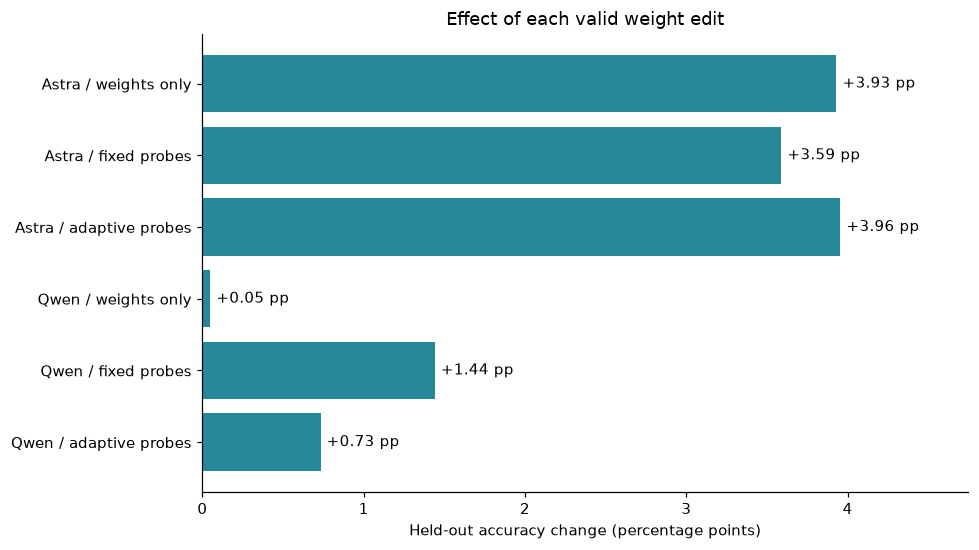

In [2]:
table=[]
for r in rows:
    a={'Reviewer / condition':label(r),'Status':r['status'],'Before %':None,'After %':None,'Change (pp)':None,'Reason':r.get('reason','')}
    if r['status']=='frozen':a.update({'Before %':round(100*r['before']['accuracy'],2),'After %':round(100*r['after']['accuracy'],2),'Change (pp)':round(100*r['accuracy_change'],2)})
    table.append(a)
display(pd.DataFrame(table))
complete=[r for r in rows if r['status']=='frozen']
if complete:
    changes=[r['accuracy_change']*100 for r in complete]; y=np.arange(len(complete))
    fig,ax=plt.subplots(figsize=(9,max(3,0.6*len(y)+1.5)))
    ax.barh(y,changes,color=['#27889a' if x>=0 else '#d47743' for x in changes]);ax.axvline(0,color='#536a74',lw=1)
    ax.set(yticks=y,yticklabels=[label(r) for r in complete],xlabel='Held-out accuracy change (percentage points)',title='Effect of each valid weight edit');ax.invert_yaxis();ax.margins(x=.2)
    for i,v in enumerate(changes):ax.annotate(f'{v:+.2f} pp',(v,i),xytext=(4 if v>=0 else -4,0),textcoords='offset points',ha='left' if v>=0 else 'right',va='center')
    fig.tight_layout();save(fig,'34_repair_v2_accuracy_changes');plt.show()

## 2. Where did accuracy change?

Each quadrant groups examples by the signs of the first two inputs. The chart uses the same vertical scale in every panel to make improvements and regressions comparable.

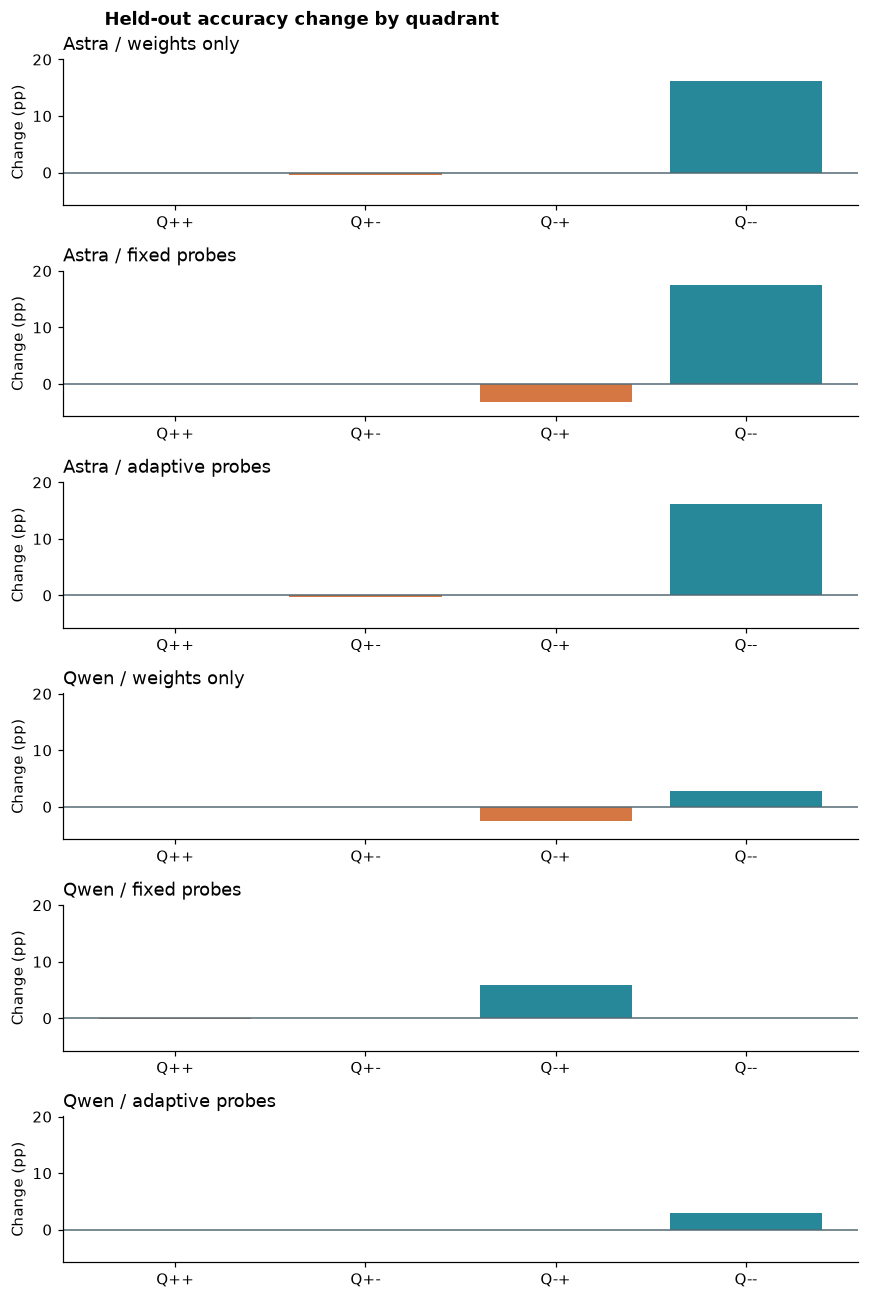

In [3]:
if complete:
    q=['Q++','Q+-','Q-+','Q--']; all_changes=[[100*(r['after']['quadrants'][x]['accuracy']-r['before']['quadrants'][x]['accuracy']) for x in q] for r in complete]
    lower=min(-1,min(min(v) for v in all_changes));upper=max(1,max(max(v) for v in all_changes));pad=(upper-lower)*.12
    fig,axes=plt.subplots(len(complete),1,figsize=(8,max(3,len(complete)*2)),squeeze=False)
    for ax,r,vals in zip(axes[:,0],complete,all_changes):
        ax.bar(q,vals,color=['#27889a' if v>=0 else '#d47743' for v in vals]);ax.axhline(0,color='#536a74',lw=1);ax.set_ylim(lower-pad,upper+pad);ax.set_ylabel('Change (pp)');ax.set_title(label(r),loc='left')
    fig.suptitle('Held-out accuracy change by quadrant',x=.125,ha='left',fontweight='bold');fig.tight_layout();save(fig,'35_repair_v2_quadrants');plt.show()

## 3. Corrections and regressions

A net gain can hide new mistakes. The same held-out examples were used before and after every edit, so we can count both errors corrected and previously correct predictions made wrong.

,Reviewer / condition,Corrected errors,New errors,Net corrected
0,Astra / weights only,165,4,161
1,Astra / fixed probes,180,33,147
2,Astra / adaptive probes,165,3,162
3,Qwen / weights only,28,26,2
4,Qwen / fixed probes,60,1,59
5,Qwen / adaptive probes,30,0,30


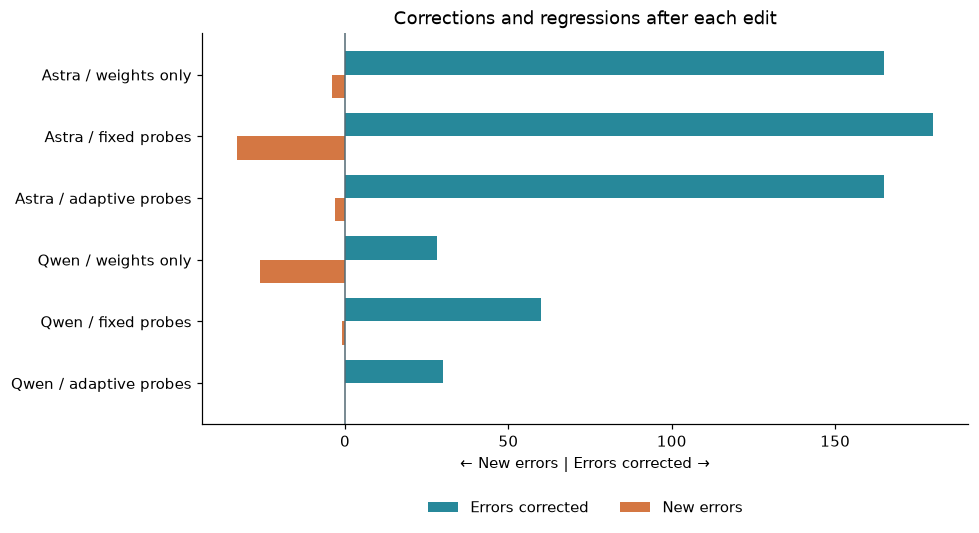

In [4]:
transitions=json.loads((ROOT/'results/repair_v2_error_transitions.json').read_text())
assert transitions['freeze_sha256']==report['freeze_sha256']
by_id={r['session_id']:r for r in rows}; records=[]
for item in transitions['sessions']:
    records.append({'Reviewer / condition':label(by_id[item['session_id']]),'Corrected errors':item['improved'],'New errors':item['regressed'],'Net corrected':item['improved']-item['regressed']})
display(pd.DataFrame(records))
y=np.arange(len(records));fig,ax=plt.subplots(figsize=(9,5));ax.barh(y-.19,[x['Corrected errors'] for x in records],.38,label='Errors corrected',color='#27889a');ax.barh(y+.19,[-x['New errors'] for x in records],.38,label='New errors',color='#d47743');ax.axvline(0,color='#536a74',lw=1);ax.set(yticks=y,yticklabels=[x['Reviewer / condition'] for x in records],xlabel='← New errors | Errors corrected →',title='Corrections and regressions after each edit');ax.invert_yaxis();ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.16),ncol=2);fig.tight_layout();save(fig,'36_repair_v2_error_transitions');plt.show()

## 4. The reviewers' proposals

The reasoning below is the reviewer's own explanation, not independently verified. An edit can improve accuracy even if the explanation is incomplete or wrong. Each reviewer had a separate conversation and could propose exactly one multiplicative edit.

In [5]:
for r in complete:
    sid=r['session_id']; folder=ROOT/'responses/raw'/sid
    filename='format_repair.txt' if (folder/'format_repair.txt').exists() else 'original.txt'
    raw=json.loads((folder/filename).read_text())
    display(Markdown('### '+label(r)))
    print('Edit:',raw['edit']);print('Hypothesis:',raw['hypothesis']);print('Expected effect:',raw['expected_effect']);print()

### Astra / weights only

Edit: {'parameter': 'fc1.weight', 'index': [3, 1], 'scale': 2}
Hypothesis: Near x0=0 with x1<0, the negative-sum feature h1[3] contributes too little positive evidence to balance the opposing features h1[1] and h1[7].
Expected effect: Move the decision boundary closer to x0=0 for negative x1, reducing false negatives when both inputs are negative. The edit leaves positive-positive predictions unchanged because h1[3] stays inactive there.



### Astra / fixed probes

Edit: {'parameter': 'fc2.weight', 'index': [None, 3], 'scale': 1.6}
Hypothesis: First-layer unit 3 detects a negative sum, but its downstream contribution is too weak to balance the difference detectors when both inputs are negative and unequal in magnitude.
Expected effect: Recover some false negatives in the negative-negative quadrant while leaving logits unchanged wherever unit 3 is inactive. The main regression risk is a false positive just across an axis when the negative input dominates.



### Astra / adaptive probes

Edit: {'parameter': 'fc1.weight', 'index': [3, 1], 'scale': 1.99}
Hypothesis: The negative-sum feature in fc1 row 3 is too weak near the negative-x1 ray: at x1 = -1, the logit does not cross zero until x0 is about -0.32. Strengthening only its x1 coefficient targets that displacement while leaving logits at x1 = 0 unchanged.
Expected effect: Move the decision boundary toward x0 = 0 for negative x1, recovering many both-negative inputs. Both-positive predictions should remain unchanged; the main regression risk is for opposite-sign inputs very close to the negative-x1 ray.



... (2 outputs left out)

### Qwen / fixed probes

Edit: {'parameter': 'fc1.weight', 'index': [2, 1], 'scale': 0.8}
Hypothesis: The 'both positive' sign detector (W1 row 2) has x1 weight 2.47 nearly equal to x0 weight 2.50, so when x0 is slightly negative and x1 is strongly positive, the x1 term dominates and the unit fires incorrectly. Scaling W1[2][1] by 0.8 reduces x1 sensitivity, making the detector require stronger x0 evidence before activating, which suppresses the false 'same sign' activation in the error case (x0=-0.073, x1=0.792) while preserving correct behavior for genuinely both-positive inputs where x0 is large enough.
Expected effect: The one misclassified probe (batch 2, input 3: x0=-0.0728, x1=0.7916, logit 15.67→~ -4.7) flips to correct negative prediction. All 31 previously correct probes remain correct with negligible logit changes (<0.1 shift in h1[2] for same-sign-positive cases).



### Qwen / adaptive probes

Edit: {'parameter': 'fc2.weight', 'index': [5, 3], 'scale': 2.0}
Hypothesis: The network fails on same-negative inputs with large magnitude asymmetry (e.g., (-0.15,-0.85)→-16.7, (-0.25,-0.75)→2.3 borderline). The cause is that h2[5] (W3 weight -2.950) fires strongly for these cases because W2[5,3]=-1.160 provides insufficient negative offset against the positive h1[1] and h1[7] contributions. Doubling W2[5,3] to -2.32 increases the h1[3] (same-sign sum) suppression of h2[5], reducing the false positive activation of this negative-contributing hidden unit for asymmetric same-negative inputs.
Expected effect: For (-0.15,-0.85): h2[5] drops from ~2.0 to ~0, recovering ~5.9 logit units → z flips from -16.7 to ~-10.8. For (-0.25,-0.75): h2[5] drops, pushing z from +2.3 to a safer margin. For (-0.9,-0.1): h2[5] drops from 1.26 to ~0.44, recovering ~2.4 units → z from -5.9 to ~-3.5 (still negative but improved). No regression on same-positive (h1[3]=0), different-sign (h1[3]≈0), or same-negat

## 5. Interpretation

This is one deliberately weakened learned checkpoint, with one conversation per reviewer and condition. Differences are descriptive; they do not establish a general ranking of models or a causal benefit from probes. A missing response limits comparisons. Development data were used to select the case, while the held-out split above was kept separate until the cohort was frozen.

For Astra, the fixed-probe edit corrected more errors than the weights-only edit (180 versus 165), but also introduced more new errors (33 versus 4). For Qwen, the fixed-probe edit corrected 60 errors and introduced one; its weights-only edit corrected 28 and introduced 26. These counts illustrate the trade-offs on this sample, not the stability of a reviewer across repeated sessions. Two Qwen final responses were wrapped in Markdown fences; removing only those fences was recorded as a format-only repair, and the original responses remain archived.